# 04 · YOLO Dataset Preparation

**Artemis-X - AI perception for lunar rock and obstacle detection**

**Objective.** Explain how curated-dataset-v1.1 became the leakage-free YOLO dataset yolo-rock-v1.1, why Config A was trained, and how uncertain regions are handled (Tasks D, D.2).

**Research questions**

1. How were train/validation/test splits built without leakage?
2. What distinguishes Config A from Config B?
3. Which assumptions does the YOLO format impose?

**Inputs (published, pixel-free artifacts)**

- `data/manifests/split_manifest.csv`
- `artifacts/data/split_statistics_v1.1.json`
- `artifacts/data/masking_audit_summary.json`

> **Provisional results.** All labels were produced by an automated pipeline (S2-H policy) and have **not** been verified by humans. Metrics are measured on synthetic renders only and do not establish performance on real lunar imagery or readiness for rover deployment.

## Setup
The notebook imports the `artemis_x` package from `src/` and reads only published artifacts. It never trains a model, rebuilds a dataset or evaluates the held-out test split.

In [1]:
import os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "artemis_x").is_dir())
sys.path.insert(0, str(ROOT / "src"))
import pandas as pd
from artemis_x.config import paths
from artemis_x.reporting import artifacts as A, plots as P
P.use_style()
pd.set_option("display.precision", 3); pd.set_option("display.max_colwidth", 90)
# Dataset pixels are never committed (redistribution licence unconfirmed). Set ARTEMIS_SHOW_LOCAL_IMAGES=1 to view
# local images when the dataset folder is present.
SHOW_LOCAL_IMAGES = os.environ.get("ARTEMIS_SHOW_LOCAL_IMAGES") == "1" and paths.local_dataset_available()
FIG = paths.ARTIFACTS / "figures"
print("artemis_x ready | local dataset present:", paths.local_dataset_available(), "| showing local images:", SHOW_LOCAL_IMAGES)

artemis_x ready | local dataset present: True | showing local images: False


## 1. YOLO label format
Each image has a text file with one line per VALID rock: `0 cx cy w h`. Here 0 is the single class `rock`, and the coordinates are
normalised to the 720 x 480 frame:
$$c_x = \frac{x_0 + x_1}{2W},\quad c_y = \frac{y_0 + y_1}{2H},\quad w = \frac{x_1 - x_0}{W},\quad h = \frac{y_1 - y_0}{H}.$$
REVIEW boxes are **not** written as labels. Images are re-encoded losslessly, and identical files are shared between dataset
versions through NTFS hard links.

## 2. Leakage-free grouped split (80 / 10 / 10)
Near-identical renders would leak information between splits. Frames were therefore grouped by:
- the dataset's duplicate lists;
- a 64-bit difference hash;
- ORB feature matching with RANSAC inliers.

Each **group** was assigned to one split, stratified by difficulty, density and uncertainty (seed 20261011). The split is fixed in
`split_manifest.csv`, which is published as metadata only.

In [2]:
from artemis_x.datasets import registry as R
sc = R.split_counts(); sc

{'splits': {'train': 7353, 'test': 917, 'val': 923},
 'config_A_train': 1903,
 'groups': 9190,
 'groups_spanning_splits': 0}

In [3]:
A.split_table()

,split,frames,fraction,VALID boxes,REVIEW boxes,VALID / image,hard scenes
0,train,7353,0.8,209430,154306,28.5,287
1,val,923,0.1,25822,19411,28.0,37
2,test,917,0.1,25987,19067,28.3,34
3,"train, Config A (trained)",1903,NaN,50060,12156,26.3,81


In [4]:
sv = A.load_json("data/split_statistics_v1.1.json")["split_validation"]
nd = sv["near_duplicates"]["audit"]
pd.Series({"eligible frames": sv["frames"], "leakage groups spanning > 1 split": len(sv["groups_spanning_multiple_splits"]),
           "image pairs checked (ORB audit)": nd["pairs_checked"], "pairs with >= 15 inliers": nd["pairs_ge_15"],
           "missed by retrieval": nd["pairs_ge_15_missed_by_retrieval"], "NASA files in export": sv["nasa_files_in_export"],
           "anomaly frames in export": sv["excluded_anomaly_frames_in_export"]}).to_frame("check")

,check
eligible frames,9193
leakage groups spanning > 1 split,0
image pairs checked (ORB audit),551520
pairs with >= 15 inliers,1
missed by retrieval,0
NASA files in export,0
anomaly frames in export,0


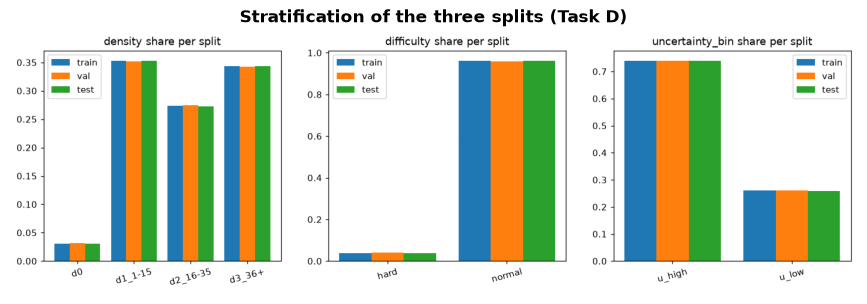

In [5]:
P.show_png(FIG / "d_split_strata.png", "Stratification of the three splits (Task D)")

## 3. Two training configurations
| | **Config A - conservative (trained)** | Config B - masked (prepared, not trained) |
|---|---|---|
| Training scenes | 1,903 scenes with REVIEW / (VALID + REVIEW) <= 0.25 | all 7,353 training scenes |
| REVIEW regions | absent from training scenes by selection | painted out with local background texture |
| Risk | fewer images; some uncertain rocks remain unlabelled | in-painting artefacts; erased real rocks |
| Validation / test | identical unmasked images and labels for both | |

**Why Config A was trained first.** Config A changes no pixels. The Task D.2 masking audit showed that Config B erases about 150,000
REVIEW boxes, including about 21,500 large ones, and that the in-painted texture is measurably flatter than real terrain. These are
risks a model could learn as a shortcut. A full A-versus-B comparison is still possible because Config B is preserved.

In [6]:
m = A.load_json("data/masking_audit_summary.json")
pd.Series({"REVIEW boxes erased (Config B)": m["erased_review_boxes_total"], "of which large": m["erased_large_review_boxes_total"],
           "changed pixels inside VALID boxes": m["changed_pixels_inside_valid_boxes_total"],
           "images with low texture ratio (< 0.5)": m["images_texture_ratio_lt_0.5"],
           "median masked fraction of an image": m["masked_fraction"]["median"]}).to_frame("Config B masking audit")

,Config B masking audit
REVIEW boxes erased (Config B),149975.000
of which large,21553.000
changed pixels inside VALID boxes,0.000
images with low texture ratio (< 0.5),6866.000
median masked fraction of an image,0.024


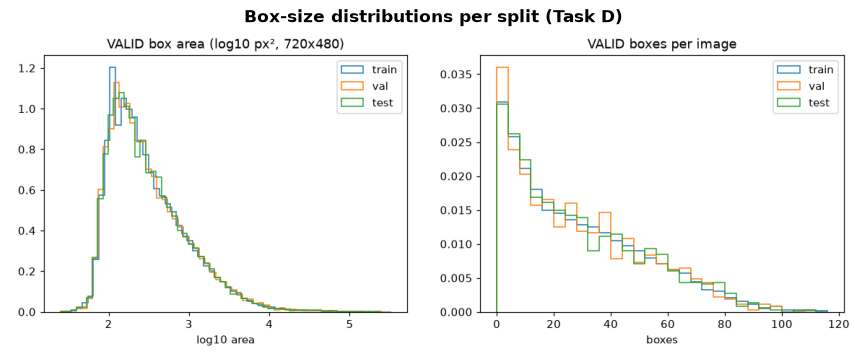

In [7]:
P.show_png(FIG / "d_split_box_distributions.png", "Box-size distributions per split (Task D)")

## 4. Integrity of the local dataset copy (if present)
The content hashes pinned in `VERSIONS.json` are compared with the files on this machine.

In [8]:
R.verify_local_yolo_dataset() if paths.local_dataset_available() else "local dataset not present - registry hashes are in artifacts/provenance/VERSIONS.json"

{'manifests/split_manifest.csv': True,
 'data_A.yaml': True,
 'data_B.yaml': True,
 'manifests/eval_ignore_regions.json': True,
 'manifests/eval_ignore_regions_subthreshold_PROPOSED.json': True}

## Provenance
Each artifact below is a verified copy (or path-sanitised derivative) of a historical experiment output; `scripts/verify_artifacts.py` re-checks every hash.

In [9]:
A.provenance(['data/split_statistics_v1.1.json', 'data/masking_audit_summary.json', 'figures/d_split_strata.png'])

,artifact,mode,source (local experiments/),sha256
0,artifacts/data/split_statistics_v1.1.json,COPY,experiments/yolo-dataset-v1.1/split_statistics.json,9be8f92355364f05...
1,artifacts/data/masking_audit_summary.json,COPY,experiments/remediation/masking_audit/masking_audit_summary.json,c24661868c59f2dc...
2,artifacts/figures/d_split_strata.png,COPY,experiments/yolo-dataset-v1.1/figures/split_strata.png,85cadee22e7efc4c...


## Conclusion
- Splits are grouped and stratified. No leakage group spans two splits, and the ORB audit found no missed near-duplicates.
- Validation and test contain **all** eligible scenes with VALID labels. REVIEW regions are not labels, and the evaluation treats
  them as ignore regions.
- Config A (1,903 scenes) was trained. Config B is preserved for a future controlled comparison.

**Next:** [05_model_training_analysis.ipynb](05_model_training_analysis.ipynb)